# СИЛАНТ · 01. Данные: подготовка, проверка качества, EDA

**Вход:** `data/raw/silant_forklift_market.xlsx` (файл заказчика).
**Выход:** `data/processed/market_long.csv` (long-формат), `data/processed/quality_*.csv`, графики в `reports/figures/`.

Ноутбук пересчитывается целиком при добавлении нового квартала в Excel (новый столбец справа) — парсер ищет блоки и кварталы по тексту, а не по номерам ячеек.

---
**Место в пайплайне:** шаг 1 из 6. Предыдущий: —. Следующий: 02 — тренды и сезонность. Запуск всех шагов: `python update.py`.

**Содержание:** 0. Настройка · 1. Загрузка и перевод в «длинный» формат · 2. Проверки качества · 3. Разведочный анализ (EDA) · 4. Выводы и ограничения · Источники

## 0. Настройка
Импорт библиотек, пути (относительно корня проекта), параметры и фиксированный seed для случайных чисел. Общие функции вынесены в модули `src/`, чтобы ноутбук содержал только логику анализа.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from silant_data import (
    load_market,
    check_totals,
    check_formula_ranges,
    basic_quality,
    detect_anomalies,
    CLASS_ORDER,
)

np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
RAW = ROOT / "data/raw/silant_forklift_market.xlsx"
OUT = ROOT / "data/processed"
FIG = ROOT / "reports/figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# единая палитра: цвет закреплён за сущностью
COL = {"ДВС": "#eb6834", "Электро": "#2a78d6", "Рынок": "#52514e"}
CLS_COL = dict(zip(CLASS_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]))
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "font.size": 10,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "lines.linewidth": 2,
    }
)
thous = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
pct = mt.PercentFormatter(1.0, decimals=0)


def qaxis(ax, idx, step=1):
    # подписи кварталов вида «I кв. 2023» вместо дат
    xs = idx.to_timestamp() if isinstance(idx, pd.PeriodIndex) else pd.DatetimeIndex(idx)
    per = pd.PeriodIndex(xs, freq="Q")
    ax.set_xticks(
        xs[::step],
        [f"{('I', 'II', 'III', 'IV')[p.quarter - 1]} кв. {p.year}" for p in per][::step],
        rotation=45,
    )


SOURCE_NOTE = "Источник: данные заказчика (СИЛАНТ); расчёты автора."
UNITS = {
    "01_anomalies": "Продажи, шт.",
    "02_market_by_type": "Продажи, шт.",
    "03_e_share": "Доля электропогрузчиков",
    "04_segments_by_class": "Продажи, шт.",
    "05_e_share_by_class": "Доля электропогрузчиков",
    "06_structure": "Доля, %",
}


def save(fig, name):
    # подпись оси Y (единицы) там, где её нет, и источник данных под рисунком
    unit = UNITS.get(name)
    if unit:
        for ax in fig.axes:
            if not ax.get_ylabel() and ax.get_label() != "<colorbar>":
                ax.set_ylabel(unit)
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.02, SOURCE_NOTE, fontsize=8, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

**Вывод по ячейке настройки.** Ячейка ничего не печатает: она подключает библиотеки, задаёт пути и единый стиль графиков, фиксирует seed (42) и создаёт папки `data/processed/` и `reports/figures/`. Дальше ноутбук читает только файл заказчика `data/raw/silant_forklift_market.xlsx`.

## 1. Загрузка и перевод в «длинный» формат

In [2]:
long, totals_file, formulas = load_market(RAW)
LAST_Q = long.quarter.max()
print(
    f"Строк: {len(long)} | кварталы: {long.quarter.min()}–{LAST_Q} ({long.quarter.nunique()} точек)"
)
print(long.groupby("type").segment.unique().apply(list).to_string())

export = long.assign(quarter=long.quarter.astype(str))
export[
    [
        "type",
        "segment",
        "cap_min",
        "cap_max",
        "capacity_class",
        "power",
        "quarter",
        "date",
        "year",
        "q",
        "units",
    ]
].to_csv(OUT / "market_long.csv", index=False, encoding="utf-8-sig")
long.head(8)

Строк: 182 | кварталы: 2023Q1–2026Q1 (13 точек)
type
ДВС        [1–1,8 т, 2–2,5 т, 3–3,5 т, 3,8–5 т, 6–8 т, 8,...
Электро    [1–1,8 т, 2–2,5 т, 3–3,5 т, 3,8–5 т, 5,5–8 т, ...


,type,segment,cap_min,cap_max,capacity_class,power,quarter,date,year,q,units,segment_raw,excel_row
0,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2023Q1,2023-03-31,2023,1,3050,"1-1,8т.",3
1,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2023Q2,2023-06-30,2023,2,3080,"1-1,8т.",3
2,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2023Q3,2023-09-30,2023,3,4050,"1-1,8т.",3
3,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2023Q4,2023-12-31,2023,4,2660,"1-1,8т.",3
4,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2024Q1,2024-03-31,2024,1,1530,"1-1,8т.",3
5,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2024Q2,2024-06-30,2024,2,3840,"1-1,8т.",3
6,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2024Q3,2024-09-30,2024,3,2870,"1-1,8т.",3
7,ДВС,"1–1,8 т",1.0,1.8,"1–1,8 т",от 10 до 50 л.с.,2024Q4,2024-12-31,2024,4,4160,"1-1,8т.",3


## 2. Проверки качества
### 2.1 Сегменты ↔ «Итого»
Сравниваем сумму сегментов с сохранённым значением строки «Итого» и проверяем, что формулы «Итого» ссылаются ровно на строки сегментов.

In [3]:
tot = check_totals(long, totals_file)
print(
    "Все кварталы сходятся:", bool(tot.ok.all()), "| макс. |расхождение| =", tot["diff"].abs().max()
)
tot.to_csv(OUT / "quality_totals.csv", index=False, encoding="utf-8-sig")
display(tot.pivot(index="quarter", columns="type", values="diff").T)
fr = check_formula_ranges(long, formulas)
fr

Все кварталы сходятся: True | макс. |расхождение| = 0


quarter,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1
type,,,,,,,,,,,,,
ДВС,0,0,0,0,0,0,0,0,0,0,0,0,0
Электро,0,0,0,0,0,0,0,0,0,0,0,0,0


,type,formula,segment_rows,formula_rows,exact_match,header_only_extra
0,ДВС,=SUM(C3:C10),3–10,3–10,True,False
1,Электро,=SUM(C13:C20),15–20,13–20,False,True


### 2.2 Полнота, нули, округление, покрытие

In [4]:
q = basic_quality(long)
q.to_csv(OUT / "quality_segments.csv", index=False, encoding="utf-8-sig")
display(q)
n_seg = long.groupby("type").segment.nunique()
print("Сегментов в файле:", n_seg.to_dict(), "| в описании кейса: ДВС 9, Электро 6")
print("Все значения кратны 10:", bool((long.units % 10 == 0).all()))
share_small = (
    long[long.cap_min >= 5.5].groupby("type").units.sum() / long.groupby("type").units.sum()
)
print("Доля сегментов ≥5,5 т в объёме за весь период:", share_small.round(4).to_dict())

,type,segment,n_quarters,n_missing,n_negative,n_zero,all_multiple_of_10,mean,min,max,cv
0,ДВС,"1–1,8 т",13,0,0,0,True,2527.0,1130,4160,0.43
1,ДВС,"2–2,5 т",13,0,0,0,True,2147.0,1150,3250,0.37
2,ДВС,"3–3,5 т",13,0,0,0,True,4444.0,1650,8520,0.47
3,ДВС,"3,8–5 т",13,0,0,0,True,748.0,260,1220,0.45
4,ДВС,6–8 т,13,0,0,0,True,130.0,40,200,0.41
5,ДВС,"8,5–10 т",13,0,0,0,True,102.0,40,180,0.38
6,ДВС,11–18 т,13,0,0,2,True,25.0,0,40,0.54
7,ДВС,20–25 т,13,0,0,9,True,4.0,0,20,1.69
8,Электро,"1–1,8 т",13,0,0,0,True,7685.0,4870,10790,0.23
9,Электро,"2–2,5 т",13,0,0,0,True,4313.0,2500,5820,0.25


Сегментов в файле: {'ДВС': 8, 'Электро': 6} | в описании кейса: ДВС 9, Электро 6
Все значения кратны 10: True
Доля сегментов ≥5,5 т в объёме за весь период: {'ДВС': 0.0258, 'Электро': 0.0049}


### 2.3 Кандидаты в аномалии
Для каждого крупного сегмента (медиана ≥ 100 шт.) — модель `log(y) = уровень + тренд + сезонные дамми` (дамми — фиктивные переменные кварталов) и внешне стьюдентизированный остаток (точка оценивается по модели, построенной без неё). Порог |t| ≥ 3. На 13 точках это фильтр «на что посмотреть», а не тест.

,type,segment,quarter,units,expected,stud_resid,dev_pct,flag
37,ДВС,"3–3,5 т",2025Q4,1650,2860,-3.75,-0.423,True
78,Электро,"2–2,5 т",2023Q1,2500,3750,-3.27,-0.333,True
48,ДВС,"3,8–5 т",2025Q2,340,510,-3.14,-0.333,True
95,Электро,"3–3,5 т",2024Q1,2740,1710,3.09,0.602,True
108,Электро,"3,8–5 т",2024Q1,430,280,3.21,0.536,True


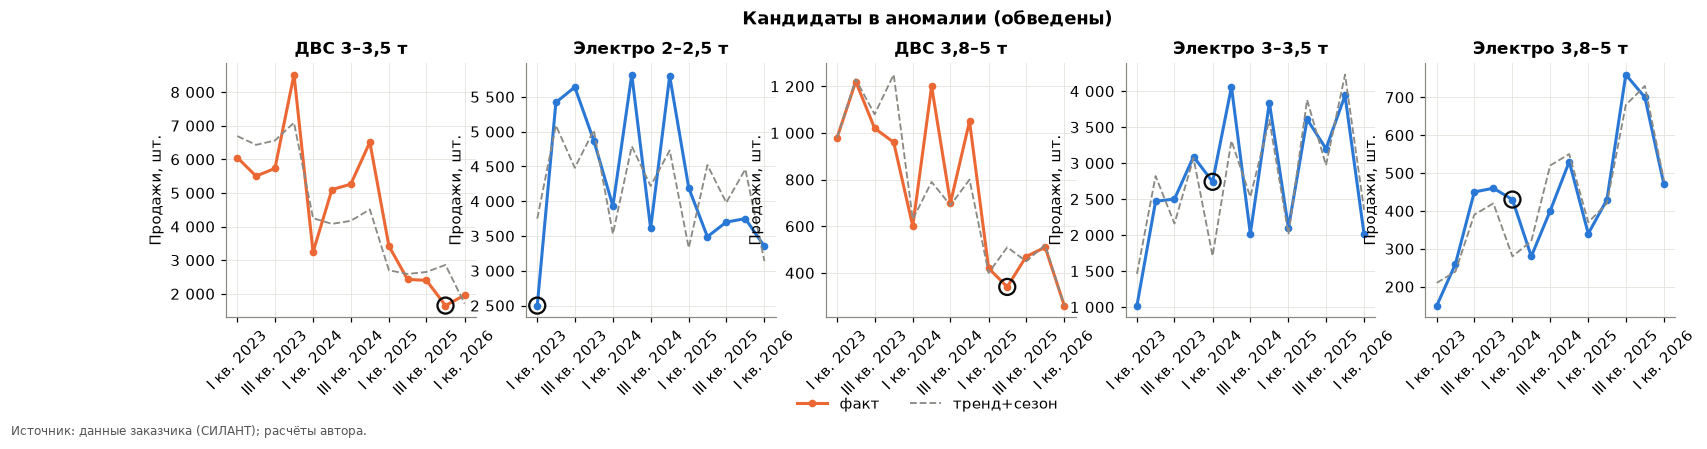

In [5]:
an = detect_anomalies(long)
an.assign(quarter=an.quarter.astype(str)).to_csv(
    OUT / "quality_anomalies.csv", index=False, encoding="utf-8-sig"
)
flag = an[an.flag].sort_values("stud_resid")
display(flag)

segs = flag[["type", "segment"]].drop_duplicates().values.tolist()
fig, axes = plt.subplots(1, len(segs), figsize=(3.4 * len(segs), 3), sharex=True)
for ax, (t, s) in zip(np.atleast_1d(axes), segs):
    d = an[(an.type == t) & (an.segment == s)]
    x = d.quarter.dt.to_timestamp()
    ax.plot(x, d.units, color=COL[t], marker="o", ms=4, label="факт")
    ax.plot(x, d.expected, color="#8a8984", ls="--", lw=1.2, label="тренд+сезон")
    f = d[d.flag]
    ax.scatter(
        f.quarter.dt.to_timestamp(),
        f.units,
        s=110,
        facecolors="none",
        edgecolors="#0b0b0b",
        lw=1.5,
        zorder=5,
    )
    ax.set_title(f"{t} {s}")
    ax.yaxis.set_major_formatter(thous)
    qaxis(ax, x, 2)
fig.legend(
    *np.atleast_1d(axes)[0].get_legend_handles_labels(),
    frameon=False,
    ncol=2,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.22),
)
fig.suptitle("Кандидаты в аномалии (обведены)", y=1.04, fontweight="bold")
save(fig, "01_anomalies")

## 3. Разведочный анализ (EDA)
### 3.1 Рынок по типам: квартал и скользящие 4 квартала (LTM)

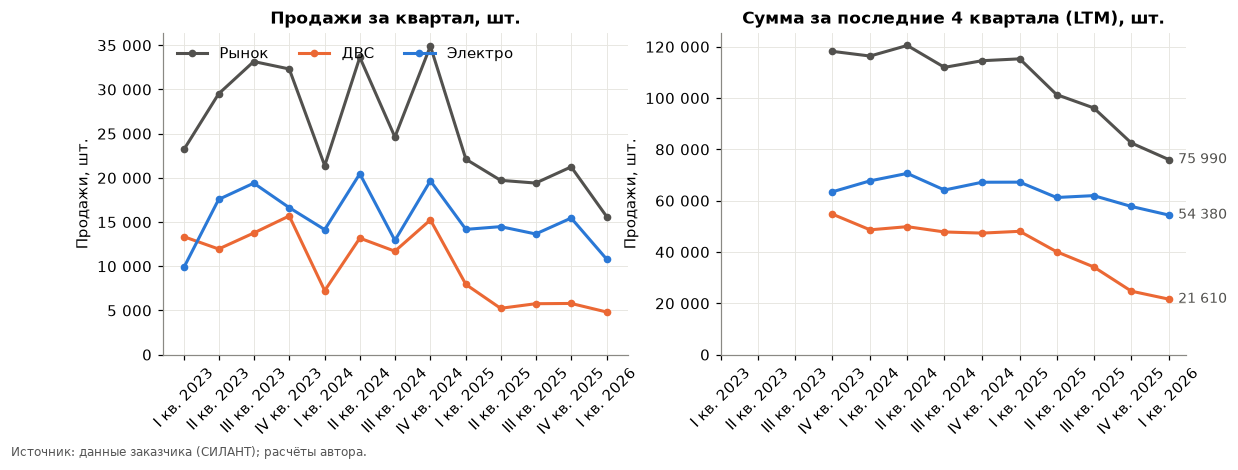

Годовые объёмы, шт.


type,ДВС,Электро,Рынок
year,,,
2023,54740,63460,118200
2024,47360,67190,114550
2025,24730,57750,82480


Изменение г/г


type,ДВС,Электро,Рынок
year,,,
2023,NaN,NaN,NaN
2024,-0.135,0.059,-0.031
2025,-0.478,-0.140,-0.280


Последний квартал 2026Q1 к тому же кварталу прошлого года:


type,ДВС,Электро,Рынок
г/г,-0.393,-0.238,-0.294


In [6]:
wide_t = long.pivot_table(index="quarter", columns="type", values="units", aggfunc="sum")
wide_t["Рынок"] = wide_t.sum(axis=1)
ltm = wide_t.rolling(4).sum()
x = wide_t.index.to_timestamp()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for c in ["Рынок", "ДВС", "Электро"]:
    ax[0].plot(x, wide_t[c], color=COL[c], marker="o", ms=4, label=c)
    ax[1].plot(x, ltm[c], color=COL[c], marker="o", ms=4, label=c)
    ax[1].annotate(
        f"{ltm[c].iloc[-1]:,.0f}".replace(",", " "),
        (x[-1], ltm[c].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#52514e",
    )
ax[0].set_title("Продажи за квартал, шт.")
ax[1].set_title("Сумма за последние 4 квартала (LTM), шт.")
for a in ax:
    a.yaxis.set_major_formatter(thous)
    a.set_ylim(bottom=0)
    qaxis(a, x)
ax[0].legend(frameon=False, ncol=3, loc="upper left")
save(fig, "02_market_by_type")

annual = long[long.year < LAST_Q.year].groupby(["year", "type"]).units.sum().unstack()
annual["Рынок"] = annual.sum(axis=1)
annual_chg = annual.pct_change().round(3)
q1 = wide_t[wide_t.index.quarter == LAST_Q.quarter].tail(2)
print("Годовые объёмы, шт.")
display(annual)
print("Изменение г/г")
display(annual_chg)
print(f"Последний квартал {LAST_Q} к тому же кварталу прошлого года:")
display((q1.iloc[-1] / q1.iloc[0] - 1).round(3).to_frame("г/г").T)

### 3.2 Доля электропогрузчиков

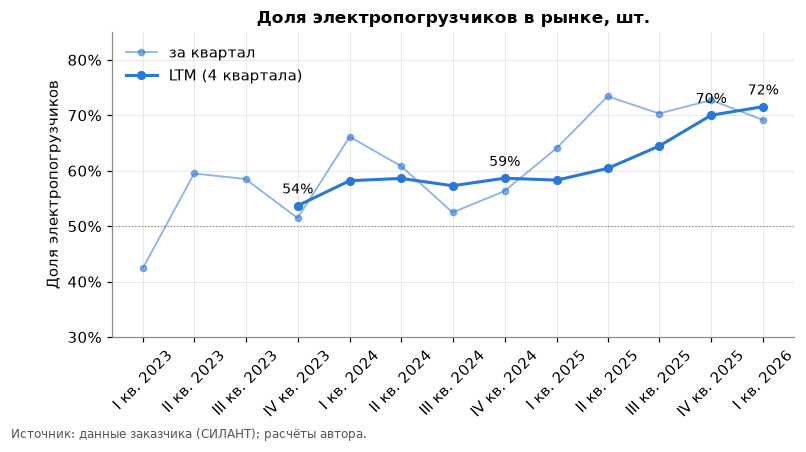

quarter,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1
квартал,0.425,0.595,0.585,0.515,0.661,0.608,0.525,0.563,0.641,0.734,0.703,0.727,0.691
LTM,NaN,NaN,NaN,0.537,0.582,0.586,0.573,0.587,0.583,0.604,0.645,0.700,0.716


In [7]:
share = wide_t["Электро"] / wide_t["Рынок"]
share_ltm = ltm["Электро"] / ltm["Рынок"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, share, color=COL["Электро"], marker="o", ms=4, lw=1.2, alpha=0.55, label="за квартал")
ax.plot(x, share_ltm, color=COL["Электро"], marker="o", ms=5, label="LTM (4 квартала)")
for xi, v in zip(x[3::4].append(x[-1:]), share_ltm.iloc[3::4].tolist() + [share_ltm.iloc[-1]]):
    ax.annotate(
        f"{v:.0%}", (xi, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9
    )
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.3, 0.85)
ax.axhline(0.5, color="#8a8984", lw=0.8, ls=":")
ax.set_title("Доля электропогрузчиков в рынке, шт.")
qaxis(ax, x)
ax.legend(frameon=False)
save(fig, "03_e_share")
display(pd.DataFrame({"квартал": share, "LTM": share_ltm}).round(3).T)

### 3.3 Динамика по сегментам
Сегменты ДВС и электро сведены в 6 сопоставимых классов грузоподъёмности (у ДВС 6–8, 8,5–10, 11–18, 20–25 т; у электро 5,5–8, 8,5–16 т → «5,5–8 т» и «8,5 т и выше»). Шкалы по оси Y у панелей разные.

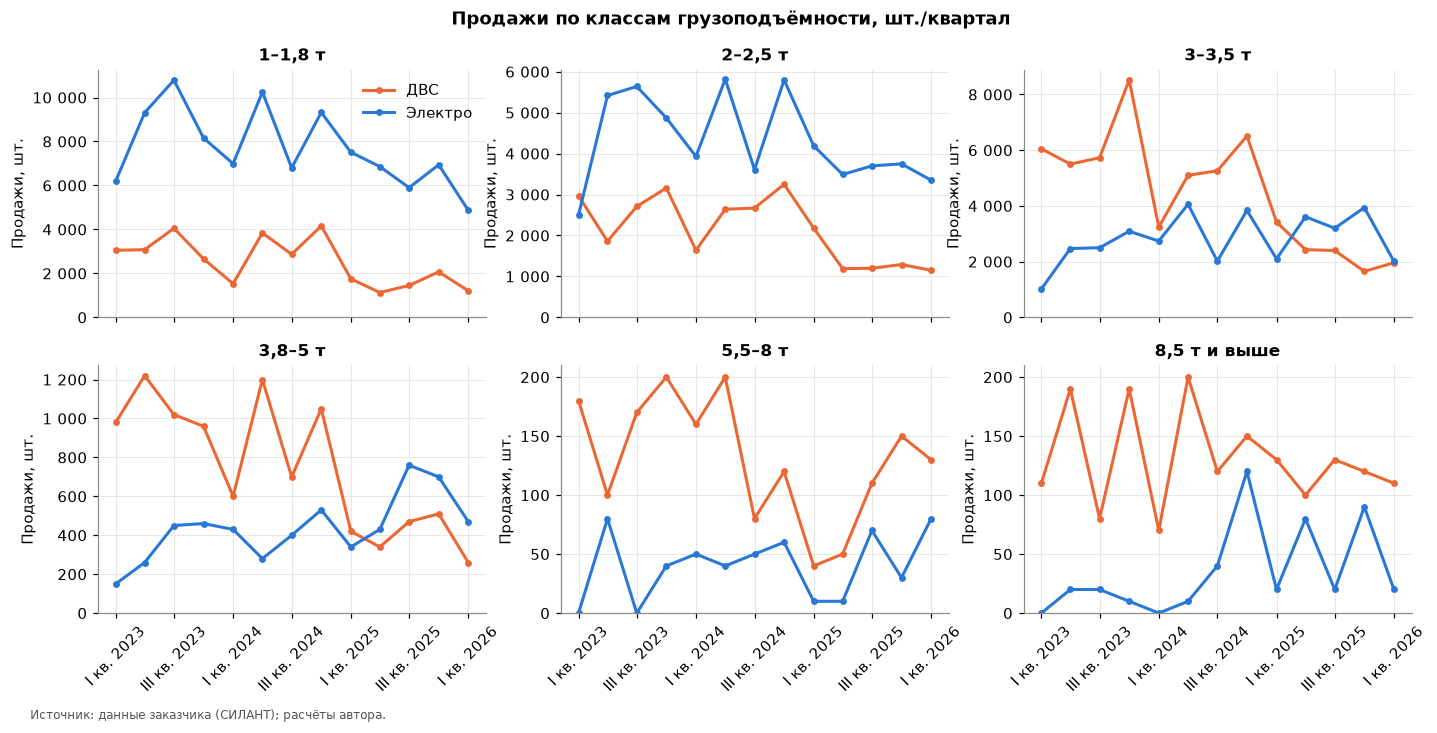

year               2023   2024   2025  Δ 2025/2023
type    segment                                   
ДВС     1–1,8 т   12840  12400   6400        -0.50
        2–2,5 т   10700  10200   5860        -0.45
        3–3,5 т   25800  20110   9900        -0.62
        3,8–5 т    4180   3550   1740        -0.58
        6–8 т       650    560    350        -0.46
        8,5–10 т    420    480    350        -0.17
        11–18 т     130     40    120        -0.08
        20–25 т      20     20     10        -0.50
Электро 1–1,8 т   34460  33360  27210        -0.21
        2–2,5 т   18430  19160  15130        -0.18
        3–3,5 т    9080  12660  12850         0.42
        3,8–5 т    1320   1640   2230         0.69
        5,5–8 т     120    200    120         0.00
        8,5–16 т     50    170    210         3.20

In [8]:
cls = long.pivot_table(
    index="quarter", columns=["capacity_class", "type"], values="units", aggfunc="sum"
)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, c in zip(axes.flat, CLASS_ORDER):
    for t in ["ДВС", "Электро"]:
        if (c, t) in cls:
            ax.plot(x, cls[(c, t)], color=COL[t], marker="o", ms=3.5, label=t)
    ax.set_title(c)
    ax.yaxis.set_major_formatter(thous)
    ax.set_ylim(bottom=0)
    qaxis(ax, x, 2)
axes[0, 0].legend(frameon=False)
fig.suptitle("Продажи по классам грузоподъёмности, шт./квартал", fontweight="bold")
fig.tight_layout()
save(fig, "04_segments_by_class")

seg_annual = long[long.year < LAST_Q.year].pivot_table(
    index=["type", "segment"], columns="year", values="units", aggfunc="sum", sort=False
)
seg_annual["Δ 2025/2023"] = (seg_annual[2025] / seg_annual[2023] - 1).round(2)
seg_annual

### 3.4 Доля электро внутри классов грузоподъёмности

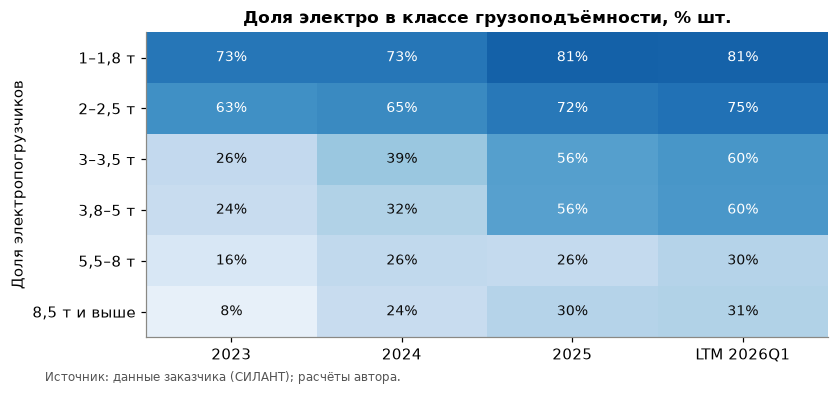

In [9]:
cls_y = long.assign(period=long.year.astype(str))
ltm_mask = long.quarter > LAST_Q - 4
cls_y = pd.concat([cls_y[cls_y.year < LAST_Q.year], long[ltm_mask].assign(period=f"LTM {LAST_Q}")])
e_share_cls = (
    cls_y.pivot_table(
        index="capacity_class", columns=["period", "type"], values="units", aggfunc="sum"
    )
    .stack("period", future_stack=True)
    .fillna(0)
)
e_share_cls = (
    (e_share_cls["Электро"] / e_share_cls.sum(axis=1)).unstack("period").reindex(CLASS_ORDER)
)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(e_share_cls.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(e_share_cls.shape[1]), e_share_cls.columns)
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
for i in range(e_share_cls.shape[0]):
    for j in range(e_share_cls.shape[1]):
        v = e_share_cls.values[i, j]
        ax.text(
            j,
            i,
            f"{v:.0%}",
            ha="center",
            va="center",
            color="white" if v > 0.55 else "#0b0b0b",
            fontsize=9,
        )
ax.grid(False)
ax.set_title("Доля электро в классе грузоподъёмности, % шт.")
save(fig, "05_e_share_by_class")

### 3.5 Структура по грузоподъёмности внутри типа

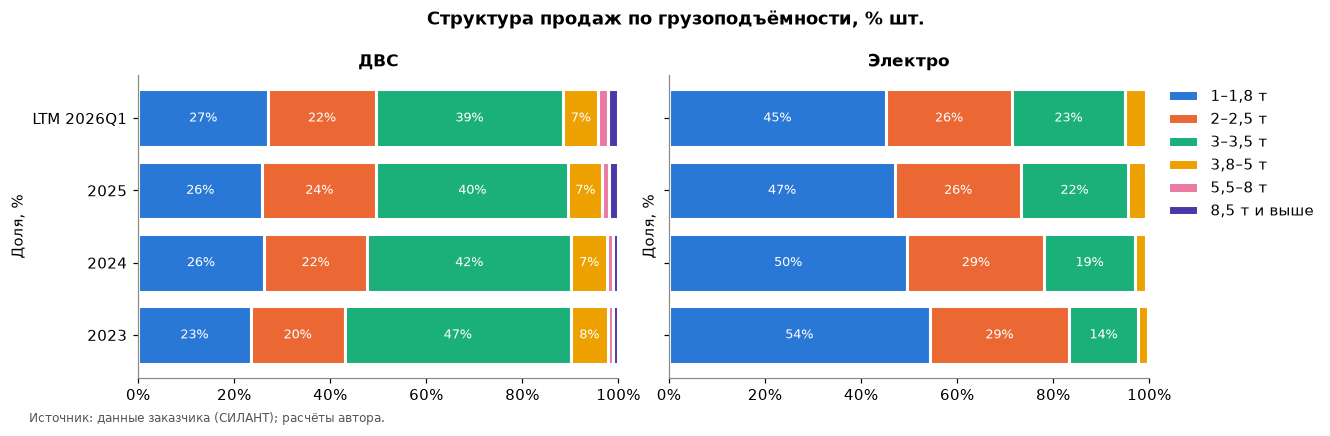

capacity_class      1–1,8 т  2–2,5 т  3–3,5 т  3,8–5 т  5,5–8 т  8,5 т и выше
type    period                                                               
ДВС     2023          0.235    0.195    0.471    0.076    0.012         0.010
        2024          0.262    0.215    0.425    0.075    0.012         0.011
        2025          0.259    0.237    0.400    0.070    0.014         0.019
        LTM 2026Q1    0.271    0.224    0.391    0.073    0.020         0.021
Электро 2023          0.543    0.290    0.143    0.021    0.002         0.001
        2024          0.497    0.285    0.188    0.024    0.003         0.003
        2025          0.471    0.262    0.223    0.039    0.002         0.004
        LTM 2026Q1    0.452    0.263    0.235    0.043    0.003         0.004

In [10]:
struct = cls_y.pivot_table(
    index=["type", "period"], columns="capacity_class", values="units", aggfunc="sum"
)[CLASS_ORDER].fillna(0)
struct = struct.div(struct.sum(axis=1), axis=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, t in zip(axes, ["ДВС", "Электро"]):
    d = struct.loc[t]
    left = np.zeros(len(d))
    for c in CLASS_ORDER:
        ax.barh(d.index, d[c], left=left, color=CLS_COL[c], edgecolor="white", lw=2, label=c)
        for yi, (l, w) in enumerate(zip(left, d[c])):
            if w > 0.06:
                ax.text(
                    l + w / 2, yi, f"{w:.0%}", ha="center", va="center", color="white", fontsize=8.5
                )
        left += d[c].values
    ax.set_title(t)
    ax.xaxis.set_major_formatter(pct)
    ax.set_xlim(0, 1)
    ax.grid(False)
    ax.invert_yaxis()
axes[1].legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Структура продаж по грузоподъёмности, % шт.", fontweight="bold")
fig.tight_layout()
save(fig, "06_structure")
struct.round(3)

### 3.6 Сезонность
Доля квартала в годовом объёме по полным годам (2023–2025). Три наблюдения на квартал — сезонность описательная, не оценённая статистически.

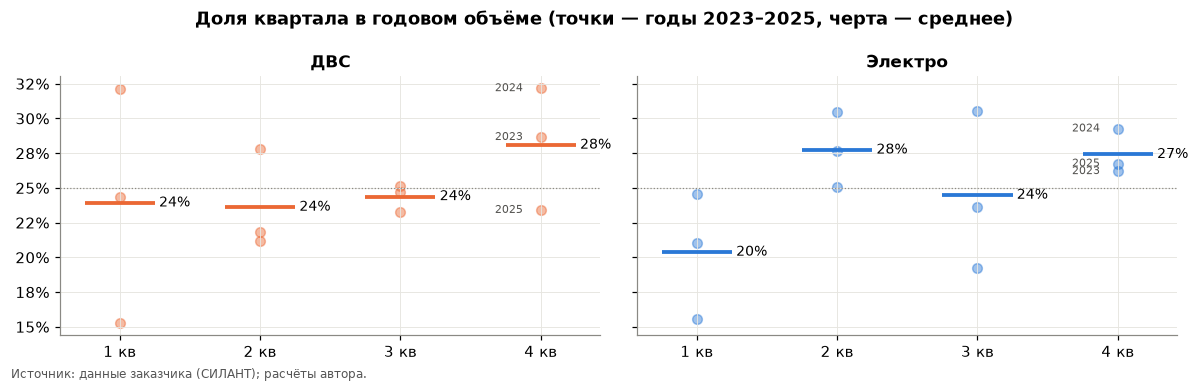

q                 1      2      3      4
type    year                            
ДВС     2023  0.244  0.218  0.251  0.287
        2024  0.153  0.278  0.247  0.322
        2025  0.321  0.212  0.233  0.234
Электро 2023  0.156  0.277  0.306  0.262
        2024  0.210  0.305  0.192  0.293
        2025  0.245  0.251  0.236  0.268

In [11]:
full = long[long.year < LAST_Q.year]
qs = full.groupby(["type", "year", "q"]).units.sum()
qs = (qs / qs.groupby(["type", "year"]).transform("sum")).unstack("q")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, t in zip(axes, ["ДВС", "Электро"]):
    d = qs.loc[t]
    for k in range(1, 5):
        ax.scatter([k] * len(d), d[k], color=COL[t], alpha=0.45, s=40)
        ax.hlines(d[k].mean(), k - 0.25, k + 0.25, color=COL[t], lw=2.5)
        ax.text(k + 0.28, d[k].mean(), f"{d[k].mean():.0%}", va="center", fontsize=9)
    for yr, row in d.iterrows():
        ax.annotate(
            str(yr),
            (4, row[4]),
            xytext=(-30, 0),
            textcoords="offset points",
            fontsize=7.5,
            color="#52514e",
            va="center",
        )
    ax.axhline(0.25, color="#8a8984", ls=":", lw=0.8)
    ax.set_xticks([1, 2, 3, 4], ["1 кв", "2 кв", "3 кв", "4 кв"])
    ax.set_title(t)
    ax.yaxis.set_major_formatter(pct)
fig.suptitle(
    "Доля квартала в годовом объёме (точки — годы 2023–2025, черта — среднее)", fontweight="bold"
)
fig.tight_layout()
save(fig, "07_seasonality")
qs.round(3)

### 3.7 Изменение г/г по сегментам (крупные сегменты)

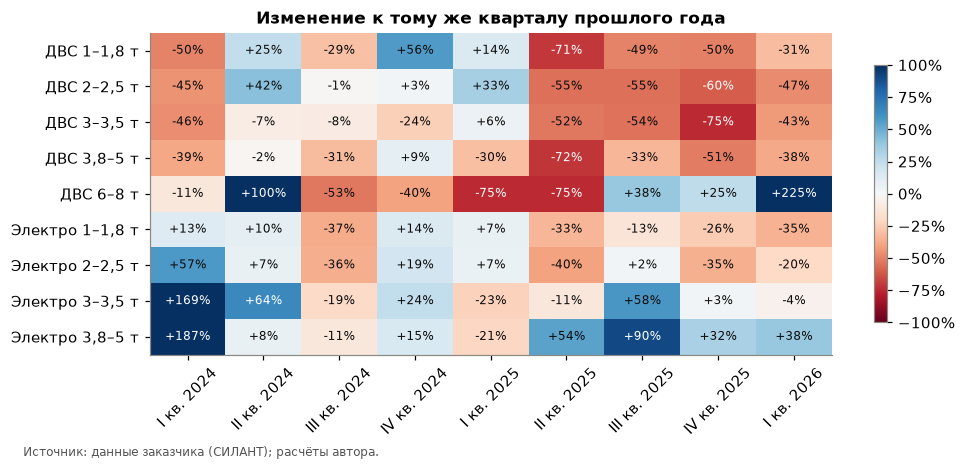

In [12]:
big = long.groupby(["type", "segment"], sort=False).units.median()
big = big[big >= 100].index
w = long.set_index(["type", "segment", "quarter"]).units.unstack("quarter").loc[big]
g = (w / w.shift(4, axis=1) - 1).iloc[:, 4:]
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(g.values, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(
    range(g.shape[1]),
    [f"{('I', 'II', 'III', 'IV')[c.quarter - 1]} кв. {c.year}" for c in g.columns],
    rotation=45,
)
ax.set_yticks(range(len(g)), [f"{a} {b}" for a, b in g.index])
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        v = g.values[i, j]
        ax.text(
            j,
            i,
            f"{v:+.0%}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(v) > 0.6 else "#0b0b0b",
        )
ax.grid(False)
ax.set_title("Изменение к тому же кварталу прошлого года")
fig.colorbar(im, ax=ax, format=pct, shrink=0.8)
save(fig, "08_yoy_heatmap")

### Проверка актуальности выводов
Текст выводов ниже написан по данным до I кв. 2026 г. Если в файле появился новый квартал, эта ячейка выведет предупреждение; таблицы и графики выше при этом пересчитываются автоматически.

In [13]:
from IPython.display import Markdown, display
from silant_data import load_market as _lm
_last = str(_lm(ROOT / 'data/raw/silant_forklift_market.xlsx')[0].quarter.max())
if _last != "2026Q1":
    display(Markdown(f"> ⚠️ **Текст выводов ниже написан по данным до 2026Q1**, а в файле данные уже до **{_last}**. "
                     "Все таблицы и графики выше пересчитаны автоматически; конкретные цифры в тексте могли устареть — "
                     "актуальные значения см. в таблицах выше, в `reports/summary.html` и `reports/silant_forecast.xlsx`."))
else:
    print("Текст выводов соответствует текущим данным (до 2026Q1).")

Текст выводов соответствует текущим данным (до 2026Q1).


## 4. Выводы и ограничения

### 4.1 Качество данных — что проверено
| Проверка | Результат | Решение |
|---|---|---|
| Сумма сегментов = «Итого» | Сходится во всех 13 кварталах по обоим типам (расхождение 0) | — |
| Диапазоны формул «Итого» | ДВС `SUM(C3:C10)` — точно по сегментам. Электро `SUM(C13:C20)` захватывает строку-заголовок блока и шапку кварталов; сейчас это не влияет (там текст, SUM его пропускает), но формула хрупкая | Пайплайн не использует «Итого» из файла, а считает его из сегментов; сверка остаётся как контроль |
| Число сегментов | ДВС — 8, а не 9, как в описании кейса; электро — 6 | Работаем с 8; уточнить у заказчика, нет ли пропущенного сегмента (например, 5–6 т ДВС) |
| Пропуски, отрицательные | Нет | — |
| Округление | Все значения кратны 10 → данные — оценка рынка с точностью ±5 шт., а не учёт продаж | Для малых сегментов это заметная погрешность |
| Нули | ДВС 20–25 т — 9 из 13 кварталов; ДВС 11–18 т, электро 5,5–8 и 8,5–16 т — по 2 нуля | Отдельные модели для сегментов ≥5,5 т не строим (2,6 % объёма ДВС, 0,5 % электро): прогноз через долю в классе/агрегат «5,5 т+» |
| Колонка «Мощность» | Для электро указана в л.с., диапазоны широкие и постоянные во времени | Справочно, в моделях не используется |

**Аномалии.** Ошибок ввода (выбросов на порядок, обнулений крупных сегментов) не найдено. Пять точек с |t| ≥ 3 объясняются содержательно:
- **ДВС 3–3,5 т IV кв. 2025 и ДВС 3,8–5 т II кв. 2025** — это не выбросы, а проявление слома тренда ДВС с II кв. 2025 (линейный тренд его не описывает);
- **Электро 2–2,5 т I кв. 2023** — начало ряда; весь электро-блок в I кв. 2023 низкий (9 870 шт., доля электро 42 % против 52–66 % в соседних кварталах). Не можем отличить реальный провал от неполного охвата первого квартала наблюдений — фиксируем как ограничение, точку не удаляем, при моделировании проверяем устойчивость без неё;
- **Электро 3–3,5 и 3,8–5 т I кв. 2024** — сильный I квартал для средней грузоподъёмности на фоне общего роста этих сегментов.

Данные не корректируем; в `quality_anomalies.csv` сохранены флаги для использования в моделях (дамми / робастная оценка).

### 4.2 Что показывает EDA
1. **Рынок сжимается, и в основном за счёт ДВС.** 2023 → 2025: рынок 118,2 → 82,5 тыс. шт. (−30 %); ДВС 54,7 → 24,7 тыс. (−55 %), электро 63,5 → 57,8 тыс. (−9 %). I кв. 2026 к I кв. 2025: рынок −29 %, ДВС −39 %, электро −24 % — спад не закончился и в 2026 затронул и электро.
2. **Слом у ДВС — во II кв. 2025**: все крупные сегменты ДВС −50…−70 % г/г с II кв. 2025 и до конца ряда; привычного пика IV квартала в 2025 не было. До этого ДВС снижались умеренно (−13 % в 2024). Причину по рыночным данным не определить — гипотезы (стоимость лизинга при ключевой ставке 21 %, изменения утильсбора, импорт) проверяем на этапе макрофакторов.
3. **Доля электро растёт скачком, а не плавно:** 54 % (2023) → 59 % (2024) → 70 % (2025) → 72 % LTM I кв. 2026. Почти весь прирост доли — следствие падения ДВС, а не роста электро в штуках.
4. **Замещение идёт снизу вверх по грузоподъёмности.** В 1–2,5 т электро уже 75–81 %; в 3–3,5 и 3,8–5 т доля выросла с ~25 % до 60 % за два года — это главный фронт замещения. Электро 3–3,5 т (+42 % за 2023→2025) и 3,8–5 т (+69 %) — единственные крупные сегменты, растущие в штуках. В ≥5,5 т электро ~30 %, но объёмы — десятки штук.
5. **Структура:** у ДВС ядро — 3–3,5 т (≈40 % штук), доля классов 1–2,5 т слегка растёт; у электро смещение в сторону более тяжёлых машин (1–1,8 т: 54 % → 45 %; 3–3,5 т: 14 % → 23 %).
6. **Сезонность слабая и нестабильная.** У электро I квартал стабильно ниже (в среднем 20 % года против 24–28 % в остальных). У ДВС сезонный профиль «переписан» сломом 2025 (в 2025 I квартал оказался крупнейшим), а пик IV квартала был в 2023–2024 и пропал в 2025. Для моделей: сезонность оценивать на рынке/электро или с сильным сжатием (shrinkage), на 3 годах отдельные сезонные коэффициенты по 14 сегментам не оцениваются надёжно.

### 4.3 Что это значит для следующих шагов
- Моделируем 8 крупных сегментов (по 4 у ДВС и электропогрузчиков) + иерархическое согласование; малые сегменты — через стабильные доли.
- В моделях ДВС нужен явный учёт слома II кв. 2025 (ступенька/дамми или обучение на данных после слома) — иначе тренд 2023–2024 даст завышенный прогноз.
- Доля электро — отдельная целевая переменная (логит-доля по классу грузоподъёмности), а не отношение двух независимых прогнозов.
- Наивные бенчмарки: сезонный наивный (тот же квартал год назад) и «последние 4 квартала».

## Источники
1. Данные: файл заказчика `data/raw/silant_forklift_market.xlsx` (продажи погрузчиков по кварталам, типам и сегментам грузоподъёмности, I кв. 2023 — I кв. 2026). Учебный кейс программы «Data Scientist: с нуля до middle» (Нетология); данные небольшие и не содержат персональных сведений.
2. Описание шагов и проверок файла: `docs/PIPELINE_NOTES.ru.md`.
3. Hyndman R.J., Athanasopoulos G. Forecasting: Principles and Practice. 3rd ed. Melbourne: OTexts, 2021. https://otexts.com/fpp3/ — графики и описательный анализ временных рядов.
4. Rule A. et al. Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks // PLoS Computational Biology. 2019. Vol. 15, № 7. e1007007.